# Inside one rise and one collapse

The γ = 0.03 control of the γ swap (`sim_analysis.ipynb`, section 10: p = 0.3, α = 0.0125, 200 × 200
lattice, largest cluster only, directed cycles of length 2-6 rejected) was continued from its last state
at t = 150M with its own random stream, keeping every state every 1,000 steps
(`tools/run_switch_capture.py`). It stopped 2M steps after its first rise to the high regime and the
collapse that followed: 18,631 states over 150-168.63M, 6.4 GB on E:. Regimes follow
`sim_analysis.ipynb`: living species smoothed over 0.2M steps, high from reaching 50 until falling to 10.

Mitarai, Mathiesen and Sneppen (2012, `emergence_of_diversity_in_a_model_ecosystem.md`) propose that:
- a rise to high diversity is triggered by an increase in patchiness: collapsing cyclic relations, or
  linear chains A → B → C, leave isolated patches in which newcomers can establish;
- a collapse is preceded by a loss of patchiness, which removes those shelters.

Here every directed cycle in Γ is at least 7 species long. Sections 3-7 test these ideas with measures
of every kept state, computed by `switch_features.py` and cached on E: as `features.npz` (about 70 s with
8 processes the first time, a second afterwards).

One rule of the model matters throughout. A newcomer always invades the species at the site it lands
on, so it spreads through that species' connected patch and, unless that species can invade it back,
takes all of it. The landed-on species survives only if it has another patch elsewhere.

In [1]:
# Load the capture: its plan, living species and patches every 1,000 steps, and the regime
# switches by the rule it stopped on.
import json
import os
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# The notebooks live in analysis/; work from the project root, so sim_modules resolves.
if Path.cwd().name == "analysis":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import sim_modules as MS
from analysis import switch_features
from tools.run_switch_capture import regime_switches

CAPTURE = Path(r"E:\MasterProject\checkpoints\switches_p0.3_a0.0125_g0.03_20261029_150918_cd0568f6")
plan = json.loads((CAPTURE / "capture_plan.json").read_text(encoding="utf-8"))
settings = plan["simulation"]
with np.load(CAPTURE / "series.npz") as saved:
    times = saved["timesteps"]
    diversity = saved["living_species"].astype(np.float64)
    patches = saved["patches"].astype(np.float64)
t_m = times / 1e6  # Millions of steps, on every axis.
STATE_FILES = switch_features.state_files(CAPTURE)  # One saved state per sample.
assert len(STATE_FILES) == times.size

LOW, HIGH = plan["regime_rule"]["low"], plan["regime_rule"]["high"]
SMOOTH = 200  # Samples: the rule's 0.2M steps at this capture's 1,000-step spacing.
smooth_d = MS._gaussian_smooth(diversity, SMOOTH)
smooth_p = MS._gaussian_smooth(patches, SMOOTH)
rate_d = np.gradient(smooth_d, t_m)  # Living species per million steps.
rate_p = np.gradient(smooth_p, t_m)
switches, _, _ = regime_switches(times, diversity, plan["regime_rule"])
RISE = next(switch["timestep"] for switch in switches if switch["up"])
COLLAPSE = next(switch["timestep"] for switch in switches
                if not switch["up"] and switch["timestep"] > RISE)
i_rise, i_collapse = (int(index) for index in np.searchsorted(times, [RISE, COLLAPSE]))

# Colours keep one meaning each. Living species use the γ-swap run's colour from
# sim_analysis.ipynb; the pairs were checked with the dataviz palette validator.
SPECIES_COLOR, PATCH_COLOR = "#6250d6", "#eb6834"
RISE_COLOR, COLLAPSE_COLOR = "#2a78d6", "#e34948"
INK, BAND_COLOR, SURFACE = "#52514e", "#ecebe6", "#fcfcfb"
RESULT_STYLE = {
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.facecolor": SURFACE,
    "axes.titlesize": 10, "axes.labelsize": 9, "axes.titlelocation": "left",
    "xtick.color": INK, "ytick.color": INK, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "legend.frameon": False, "legend.fontsize": 8, "figure.facecolor": "white",
}

print(f"{times.size:,} states, t = {t_m[0]:g}M -> {t_m[-1]:g}M every {plan['track_every']:,} "
      f"steps; p = {settings['p']:g}, α = {settings['alpha']:g}, γ = {settings['gamma']:g}, "
      f"cycles 2-{settings['max_forbidden_cycle_length']} rejected, "
      f"{settings['usable_sites']:,} usable sites")
print(f"Rise to {HIGH} living species at t = {RISE / 1e6:.2f}M; "
      f"collapse to {LOW} at t = {COLLAPSE / 1e6:.2f}M (smoothed)")

18,631 states, t = 150M -> 168.63M every 1,000 steps; p = 0.3, α = 0.0125, γ = 0.03, cycles 2-6 rejected, 27,482 usable sites
Rise to 50 living species at t = 154.45M; collapse to 10 at t = 166.63M (smoothed)


## 1. Living species and patches

Living species (solid, left axis) and single-species patches (dashed, right axis) on the same time axis.
Thin lines are the raw samples every 1,000 steps and thick lines are smoothed over 0.2M steps. Each axis
runs from 0 to its highest sample in the panel, so the two curves are scaled to match. The lower panels
show the rise and the collapse in detail, with 0.3M steps of context on each side.

The numbered lines mark the five snapshots of section 2, picked from the smoothed living species:
1. **Before the rise**: the low point the rise starts from.
2. **Steepest rise**: the fastest increase between that low point and the peak the rise reaches.
3. **High diversity**: the most living species between the rise and the collapse.
4. **Steepest collapse**: the fastest decline between the last peak before the collapse and the collapse.
5. **Low after the collapse**: the fewest living species after the collapse.

Restricting 2 to the rise matters: over the whole capture the fastest growth (at about 161.7M) is a
recovery inside the high regime, not the switch.

1. Before the rise         t = 153.076M:  13 living species (smoothed  21.6,   +0.0 per 1M steps),  127 patches
2. Steepest rise           t = 154.612M:  65 living species (smoothed  62.8,  +80.1 per 1M steps),  793 patches
3. High diversity          t = 156.285M: 120 living species (smoothed 115.7,   -0.0 per 1M steps),  879 patches
4. Steepest collapse       t = 163.953M:  83 living species (smoothed  85.2,  -91.0 per 1M steps),  591 patches
5. Low after the collapse  t = 166.736M:   4 living species (smoothed   9.4,   +0.0 per 1M steps),   21 patches


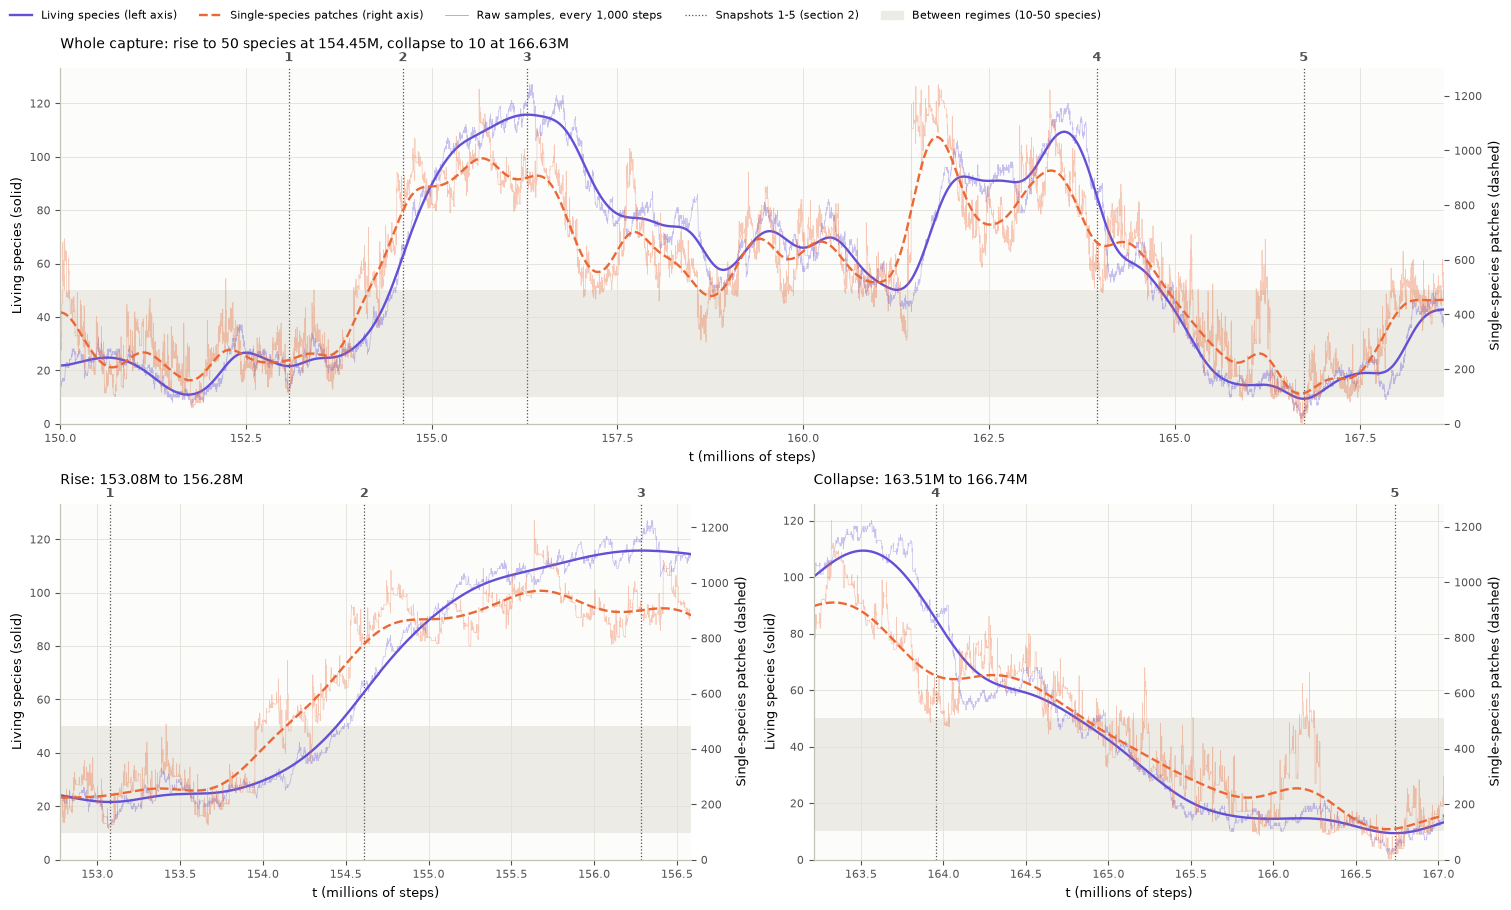

In [2]:
# The five snapshots and the two windows, picked as described above. The videos of
# tools/render_switch_videos.py use the same windows.
points = switch_features.switch_points(times, diversity, plan["regime_rule"], smooth=SMOOTH)
# Replace an entry to look at another time, e.g. int(np.searchsorted(times, 152_000_000)).
SNAPSHOTS = points["snapshots"]
WINDOWS = points["windows"]
i_trough = WINDOWS["Rise"][0]  # The low point the rise starts from.
for number, (name, index) in enumerate(SNAPSHOTS.items(), 1):
    print(f"{number}. {name:23s} t = {t_m[index]:7.3f}M: {diversity[index]:3.0f} living species "
          f"(smoothed {smooth_d[index]:5.1f}, {rate_d[index]:+6.1f} per 1M steps), "
          f"{patches[index]:4.0f} patches")


def plot_overlay(ax, lo, hi):
    # Living species (left axis) and patches (right axis) over samples lo to hi.
    part = slice(lo, hi + 1)
    twin = ax.twinx()
    twin.grid(False)
    ax.axhspan(LOW, HIGH, color=BAND_COLOR, lw=0, zorder=0)
    for axis, raw, smooth, color, ls in ((ax, diversity, smooth_d, SPECIES_COLOR, "-"),
                                         (twin, patches, smooth_p, PATCH_COLOR, "--")):
        axis.plot(t_m[part], raw[part], color=color, lw=0.5, alpha=0.35)
        axis.plot(t_m[part], smooth[part], color=color, lw=1.7, ls=ls)
        axis.set_ylim(0, 1.05 * raw[part].max())
    for number, index in enumerate(SNAPSHOTS.values(), 1):
        if lo <= index <= hi:
            ax.axvline(t_m[index], color=INK, lw=0.9, ls=":", zorder=1)
            ax.text(t_m[index], 1.01, str(number), transform=ax.get_xaxis_transform(),
                    ha="center", va="bottom", fontsize=9, fontweight="bold", color=INK)
    ax.set_xlim(t_m[lo], t_m[hi])
    ax.set_ylabel("Living species (solid)")
    twin.set_ylabel("Single-species patches (dashed)")
    ax.set_xlabel("t (millions of steps)")


with plt.rc_context(RESULT_STYLE):
    fig = plt.figure(figsize=(15, 9), layout="constrained")
    grid = fig.add_gridspec(2, 2)
    top = fig.add_subplot(grid[0, :])
    plot_overlay(top, 0, times.size - 1)
    top.set_title(f"Whole capture: rise to {HIGH} species at {RISE / 1e6:.2f}M, collapse to {LOW} "
                  f"at {COLLAPSE / 1e6:.2f}M", pad=14)
    PAD = 300  # Samples (0.3M steps) of context either side of a window.
    for column, (name, (lo, hi)) in enumerate(WINDOWS.items()):
        ax = fig.add_subplot(grid[1, column])
        plot_overlay(ax, max(lo - PAD, 0), min(hi + PAD, times.size - 1))
        ax.set_title(f"{name}: {t_m[lo]:.2f}M to {t_m[hi]:.2f}M", pad=14)
    fig.legend(handles=[
        Line2D([], [], color=SPECIES_COLOR, lw=1.7, label="Living species (left axis)"),
        Line2D([], [], color=PATCH_COLOR, lw=1.7, ls="--", label="Single-species patches (right axis)"),
        Line2D([], [], color=INK, lw=0.5, alpha=0.6, label="Raw samples, every 1,000 steps"),
        Line2D([], [], color=INK, lw=0.9, ls=":", label="Snapshots 1-5 (section 2)"),
        Patch(color=BAND_COLOR, label=f"Between regimes ({LOW}-{HIGH} species)"),
    ], loc="outside upper left", ncols=5)
    plt.show()

## 2. Five lattice snapshots

Top row: the lattice, one colour per species (colours follow species IDs, so they are consistent within
this run only); black sites are blocked. Bottom row: the same sites by whether their species lives in a
single patch (grey) or in several (blue). A newcomer landing on a grey site can erase that species; a
species in blue survives the loss of one patch.

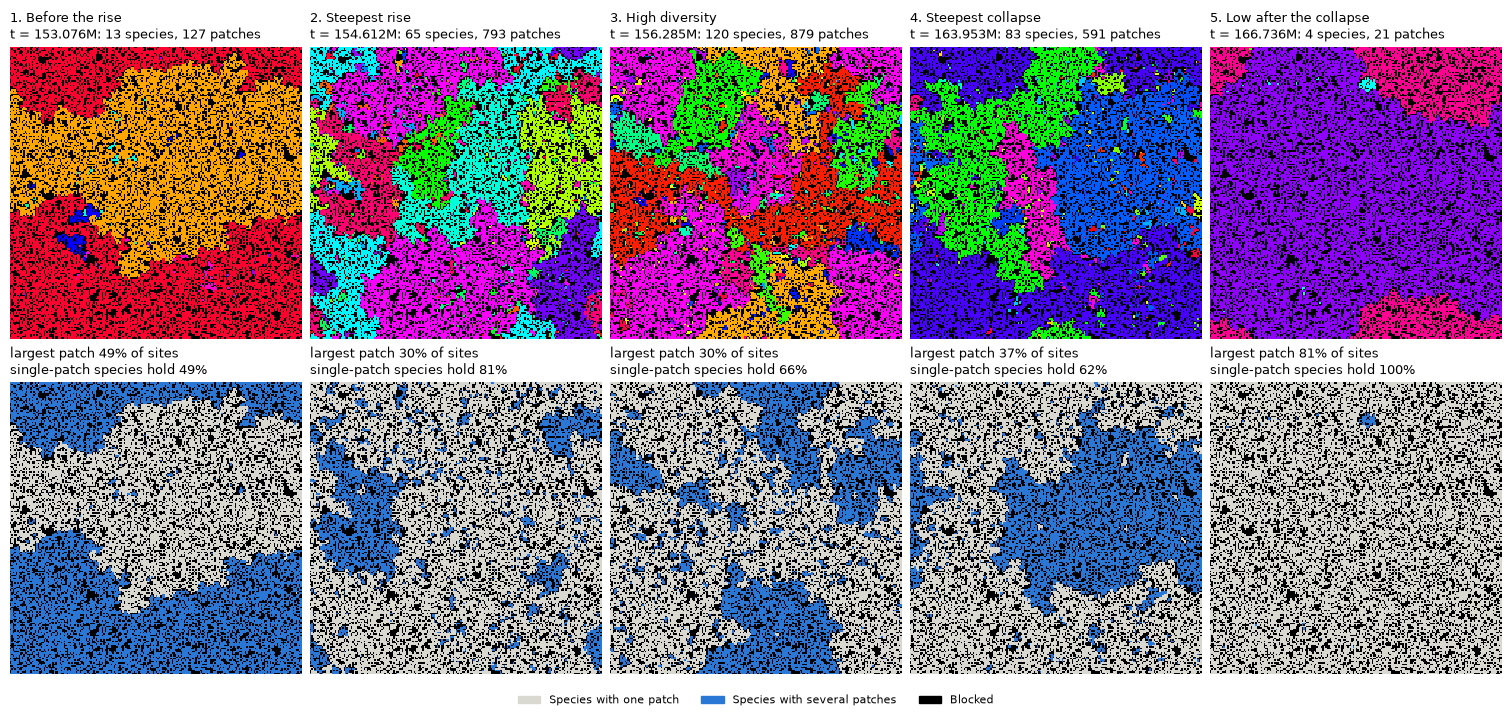

In [3]:
SINGLE_COLOR, SEVERAL_COLOR = np.array([0.85, 0.85, 0.82]), np.array([0.165, 0.47, 0.84])

with plt.rc_context(RESULT_STYLE):
    fig, axes = plt.subplots(2, len(SNAPSHOTS), figsize=(15, 7.0), layout="constrained")
    for column, (name, index) in enumerate(SNAPSHOTS.items()):
        state = MS.load_checkpoint(STATE_FILES[index])
        lattice = state["lattice"]
        info = switch_features.state_features(STATE_FILES[index])
        # Patches of each site's species, through the species' row in info.
        occupied = lattice > 0
        order = np.argsort(info["species_id"])
        row = order[np.searchsorted(info["species_id"][order], lattice[occupied])]
        shelter = np.zeros(lattice.shape + (3,))
        shelter[occupied] = np.where((info["patches_per_species"][row] > 1)[:, None],
                                     SEVERAL_COLOR, SINGLE_COLOR)
        axes[0, column].imshow(MS._lattice_rgba(lattice), interpolation="nearest")
        axes[0, column].set_title(f"{column + 1}. {name}\nt = {t_m[index]:.3f}M: "
                                  f"{state['diversity']} species, {info['patches']} patches",
                                  fontsize=9)
        axes[1, column].imshow(shelter, interpolation="nearest")
        axes[1, column].set_title(f"largest patch {info['largest_patch_share']:.0%} of sites\n"
                                  f"single-patch species hold {info['single_patch_share']:.0%}",
                                  fontsize=9)
    for ax in axes.flat:
        ax.set_axis_off()
    fig.legend(handles=[Patch(color=SINGLE_COLOR, label="Species with one patch"),
                        Patch(color=SEVERAL_COLOR, label="Species with several patches"),
                        Patch(color="black", label="Blocked")],
               loc="outside lower center", ncols=3)
    plt.show()

## 3. Does patchiness lead diversity?

Left: smoothed patches against smoothed living species over the whole capture (grey), with the rise in
blue and the collapse in red; the dots mark where each starts. If both directions followed the same path,
patches would be a function of living species alone. Right: progress of each window, from 0 at its start
to 1 at its end, for living species and patches. The text gives when each has made half of its change,
and when each changes fastest.

Rise: half of the change in patches at 154.292M and in living species at 154.686M (patches +0.39M ahead); fastest change in patches at 154.475M and in living species at 154.612M (+0.14M ahead)
Collapse: half of the change in patches at 164.867M and in living species at 164.485M (patches -0.38M ahead); fastest change in patches at 163.713M and in living species at 163.953M (+0.24M ahead)


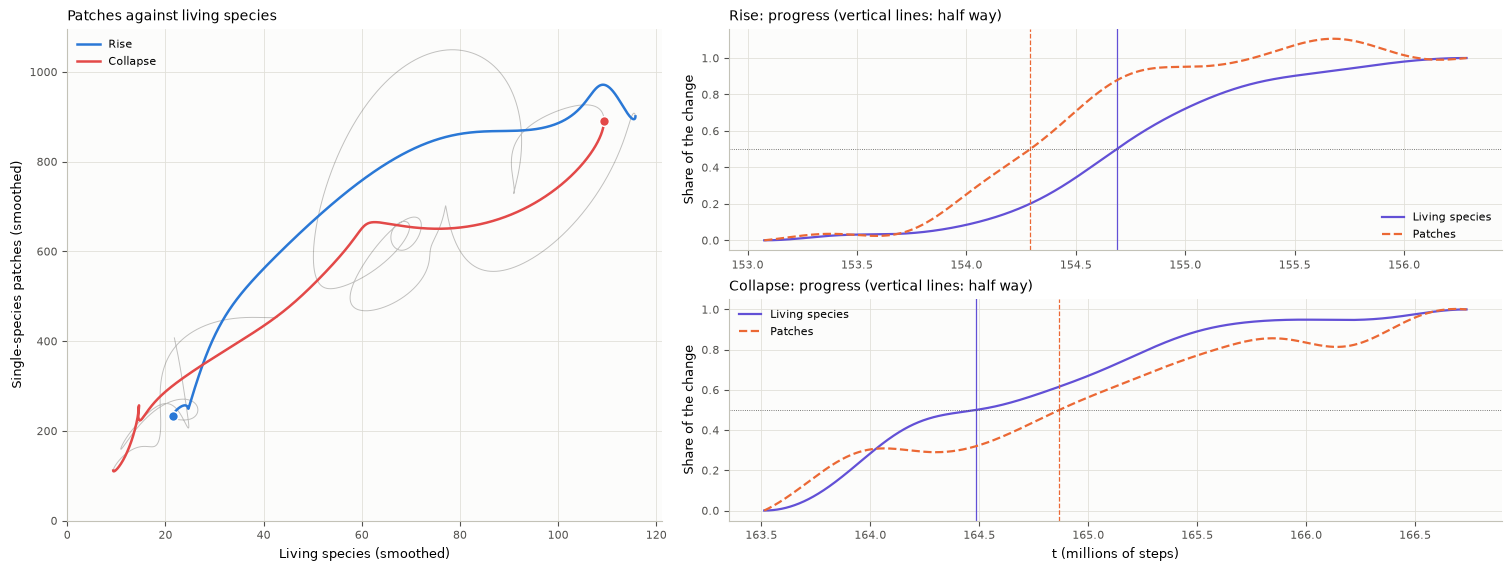

In [4]:
def half_way(values, lo, hi):
    # First sample in lo..hi at which values has made half of its change over the window.
    target = 0.5 * (values[lo] + values[hi])
    part = values[lo:hi + 1]
    crossed = part >= target if values[hi] > values[lo] else part <= target
    return lo + int(np.argmax(crossed))


timing = {}
for name, (lo, hi) in WINDOWS.items():
    timing[name] = {
        "half species": half_way(smooth_d, lo, hi), "half patches": half_way(smooth_p, lo, hi),
        "fastest species": lo + int(np.argmax(np.abs(rate_d[lo:hi + 1]))),
        "fastest patches": lo + int(np.argmax(np.abs(rate_p[lo:hi + 1]))),
    }
    marks = timing[name]
    print(f"{name}: half of the change in patches at {t_m[marks['half patches']]:.3f}M and in "
          f"living species at {t_m[marks['half species']]:.3f}M (patches "
          f"{t_m[marks['half species']] - t_m[marks['half patches']]:+.2f}M ahead); fastest change "
          f"in patches at {t_m[marks['fastest patches']]:.3f}M and in living species at "
          f"{t_m[marks['fastest species']]:.3f}M "
          f"({t_m[marks['fastest species']] - t_m[marks['fastest patches']]:+.2f}M ahead)")

with plt.rc_context(RESULT_STYLE):
    fig = plt.figure(figsize=(15, 5.6), layout="constrained")
    grid = fig.add_gridspec(2, 2, width_ratios=[1, 1.3])
    ax = fig.add_subplot(grid[:, 0])
    ax.plot(smooth_d, smooth_p, color=INK, lw=0.7, alpha=0.35)
    for (name, (lo, hi)), color in zip(WINDOWS.items(), (RISE_COLOR, COLLAPSE_COLOR)):
        ax.plot(smooth_d[lo:hi + 1], smooth_p[lo:hi + 1], color=color, lw=1.8, label=name)
        ax.plot(smooth_d[lo], smooth_p[lo], "o", color=color, ms=7, mec="white")
    ax.set(xlabel="Living species (smoothed)", ylabel="Single-species patches (smoothed)",
           title="Patches against living species", xlim=(0, None), ylim=(0, None))
    ax.legend(loc="upper left")
    for row, (name, (lo, hi)) in enumerate(WINDOWS.items()):
        ax = fig.add_subplot(grid[row, 1])
        for values, color, ls, label in ((smooth_d, SPECIES_COLOR, "-", "Living species"),
                                         (smooth_p, PATCH_COLOR, "--", "Patches")):
            progress = (values[lo:hi + 1] - values[lo]) / (values[hi] - values[lo])
            ax.plot(t_m[lo:hi + 1], progress, color=color, ls=ls, lw=1.6, label=label)
            ax.axvline(t_m[timing[name]["half " + label.split()[-1].lower()]], color=color,
                       ls=ls, lw=0.9)
        ax.axhline(0.5, color=INK, lw=0.6, ls=":")
        ax.set(ylabel="Share of the change", title=f"{name}: progress (vertical lines: half way)")
        ax.legend(loc="lower right" if name == "Rise" else "upper left")
    ax.set_xlabel("t (millions of steps)")
    plt.show()

## 4. Introductions, extinctions and which newcomers establish

New species arrive at a constant α·γ per time unit (375 per 1M steps), so a rise or a collapse can only
come from how many species die. Every species lost in a 1,000-step interval is one that was alive at its
start or arrived during it and is gone at its end. A newcomer counts as **established** when it survives
0.1M steps. Its arrival is the first sample whose newest species ID has reached its own ID; newcomers
that died within 1,000 steps were never sampled.

7,023 species arrived (377 per 1M steps); 532 died within 1,000 steps; 27% of those that can be judged established
Established by arrival bin, before the rise (150.00M to 153.08M): 7% to 26% (lowest for arrivals around 151.62M)
Established by arrival bin, rise (153.08M to 156.28M): 11% to 44% (lowest for arrivals around 153.12M)
Established by arrival bin, collapse (163.51M to 166.74M): 2% to 43% (lowest for arrivals around 166.62M)
Most species lost: 76 in the 0.1M steps around 164.05M (arrivals then: 47)


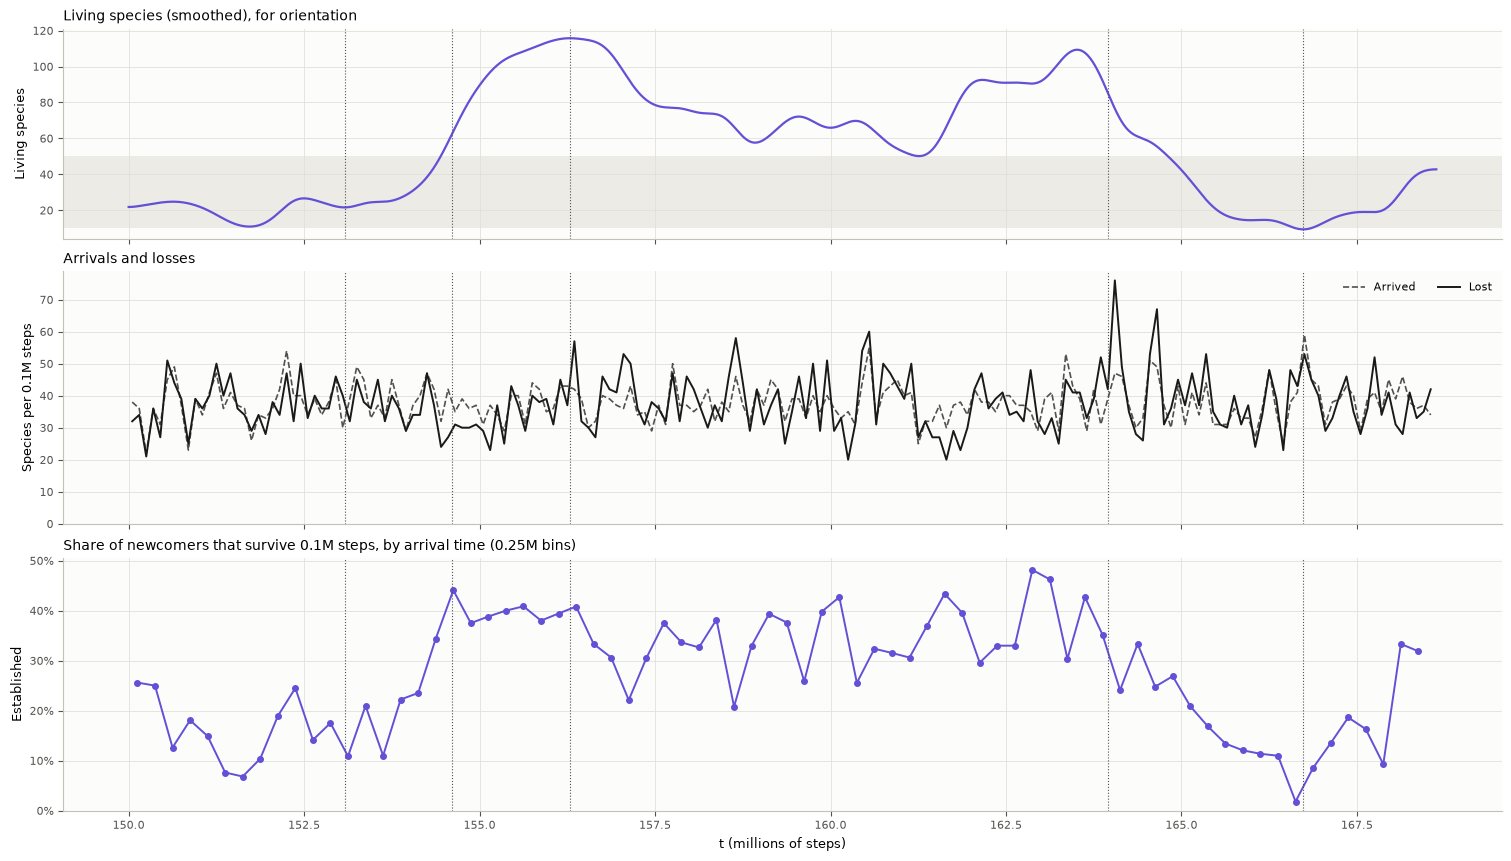

In [5]:
features = switch_features.load_features(CAPTURE)
assert np.array_equal(features["timestep"], times)
offsets, species_id = features["offsets"], features["species_id"]

arrived = np.diff(features["introduced"])  # New species per 1,000-step interval.
lost = diversity[:-1] + arrived - diversity[1:]
BIN = 100  # Intervals per bin: 0.1M steps.
bins = (times.size - 1) // BIN
bin_t = t_m[1:bins * BIN + 1].reshape(bins, BIN).mean(axis=1)
arrived_bin = arrived[:bins * BIN].reshape(bins, BIN).sum(axis=1)
lost_bin = lost[:bins * BIN].reshape(bins, BIN).sum(axis=1)

# Lifetimes of the species introduced during the capture.
sample_of_row = np.repeat(np.arange(times.size), np.diff(offsets))
order = np.argsort(species_id, kind="stable")
seen_ids, first_row = np.unique(species_id[order], return_index=True)
last_sample = np.maximum.reduceat(sample_of_row[order], first_row)
newcomers = np.arange(int(features["introduced"][0]) + 1, int(features["introduced"][-1]) + 1)
arrival = np.searchsorted(features["introduced"], newcomers)
position = np.minimum(np.searchsorted(seen_ids, newcomers), seen_ids.size - 1)
sampled = seen_ids[position] == newcomers  # The others died within 1,000 steps of arriving.
lifetime = np.where(sampled, last_sample[position] - arrival + 1, 0) * plan["track_every"]
ESTABLISHED = 100_000  # Steps a newcomer must survive to count as established.
judged = arrival + ESTABLISHED // plan["track_every"] < times.size
established = lifetime >= ESTABLISHED
print(f"{newcomers.size:,} species arrived ({arrived.sum() / (t_m[-1] - t_m[0]):.0f} per 1M steps); "
      f"{np.count_nonzero(~sampled):,} died within 1,000 steps; {established[judged].mean():.0%} of "
      f"those that can be judged established")

ARRIVAL_BIN = 0.25  # Millions of steps.
edges = np.arange(t_m[0], t_m[-1] + ARRIVAL_BIN, ARRIVAL_BIN)
arrival_t = t_m[np.minimum(arrival, times.size - 1)]
which = np.digitize(arrival_t, edges) - 1
counts = np.bincount(which[judged], minlength=edges.size)[:edges.size - 1]
hits = np.bincount(which[judged & established], minlength=edges.size)[:edges.size - 1]
centres = edges[:-1] + ARRIVAL_BIN / 2
keep = counts >= 20
binned = np.where(keep, hits / np.maximum(counts, 1), np.nan)
spans = {"before the rise": (t_m[0], t_m[i_trough]), "rise": tuple(t_m[list(WINDOWS["Rise"])]),
         "collapse": tuple(t_m[list(WINDOWS["Collapse"])])}
for name, (start, stop) in spans.items():
    inside = keep & (centres >= start) & (centres <= stop)
    low_bin = np.flatnonzero(inside)[np.nanargmin(binned[inside])]
    print(f"Established by arrival bin, {name} ({start:.2f}M to {stop:.2f}M): "
          f"{np.nanmin(binned[inside]):.0%} to {np.nanmax(binned[inside]):.0%} "
          f"(lowest for arrivals around {centres[low_bin]:.2f}M)")
peak_bin = int(np.argmax(lost_bin))
print(f"Most species lost: {lost_bin[peak_bin]:.0f} in the 0.1M steps around {bin_t[peak_bin]:.2f}M "
      f"(arrivals then: {arrived_bin[peak_bin]:.0f})")

with plt.rc_context(RESULT_STYLE):
    fig, axes = plt.subplots(3, 1, figsize=(15, 8.5), sharex=True, layout="constrained",
                             gridspec_kw={"height_ratios": [1, 1.2, 1.2]})
    axes[0].axhspan(LOW, HIGH, color=BAND_COLOR, lw=0)
    axes[0].plot(t_m, smooth_d, color=SPECIES_COLOR, lw=1.6)
    axes[0].set(ylabel="Living species", title="Living species (smoothed), for orientation")
    axes[1].plot(bin_t, arrived_bin, color=INK, lw=1.2, ls="--", label="Arrived")
    axes[1].plot(bin_t, lost_bin, color="#1a1a19", lw=1.4, label="Lost")
    axes[1].set(ylabel="Species per 0.1M steps", title="Arrivals and losses", ylim=(0, None))
    axes[1].legend(loc="upper right", ncols=2)
    axes[2].plot(centres[keep], hits[keep] / counts[keep], "o-", color=SPECIES_COLOR, lw=1.4, ms=4)
    axes[2].set(ylabel="Established", ylim=(0, None), xlabel="t (millions of steps)",
                title=f"Share of newcomers that survive {ESTABLISHED / 1e6:g}M steps, by arrival time "
                      f"({ARRIVAL_BIN:g}M bins)")
    axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    for ax in axes:
        for index in SNAPSHOTS.values():
            ax.axvline(t_m[index], color=INK, lw=0.8, ls=":")
    plt.show()

## 5. Space: how much of the lattice one patch holds

Three measures of every state, smoothed over 0.2M steps:
- the share of usable sites in the **largest single patch**;
- the share held by species that live in **one patch** (the chance that a random introduction erases the
  species it lands on);
- the share held by **uninvadable** species, those that no living species can invade.

The second figure relates establishment to the largest patch at the newcomer's arrival.

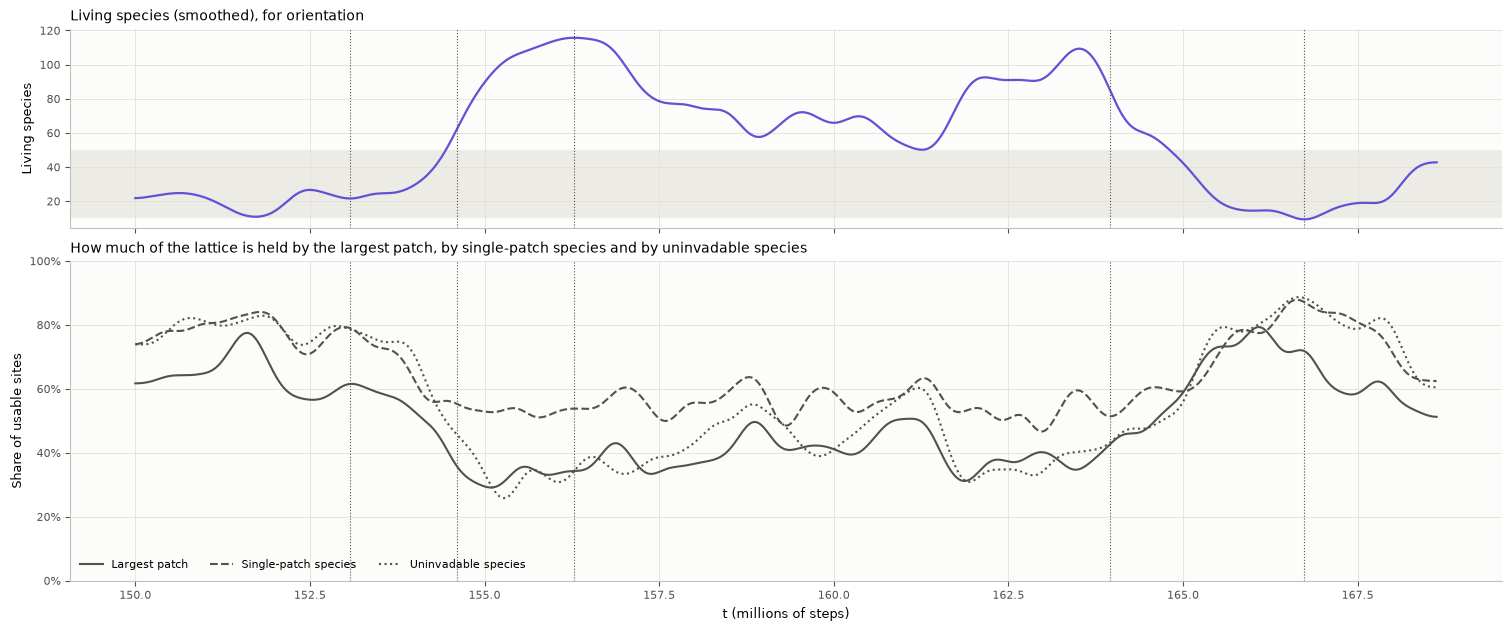

phase                    largest patch single-patch uninvadable patches/species frozen new dominant/1M established
Low, before the rise               62%          75%         76%            12.4    81%             229         18%
High                               44%          58%         47%             9.9    80%             189         32%
Low, after the collapse            61%          76%         78%            13.4    80%             249         17%
At snapshot 5 the dominant species (62425) holds 81% of the sites; it arrived between 166.734M and 166.735M, at most 2,000 steps earlier
Rise: the largest patch goes from 62% to 34% of the sites and makes half of that change at 154.249M, living species at 154.686M (+0.44M later)
Collapse: the largest patch goes from 35% to 72% of the sites and makes half of that change at 164.756M, living species at 164.485M (-0.27M later)


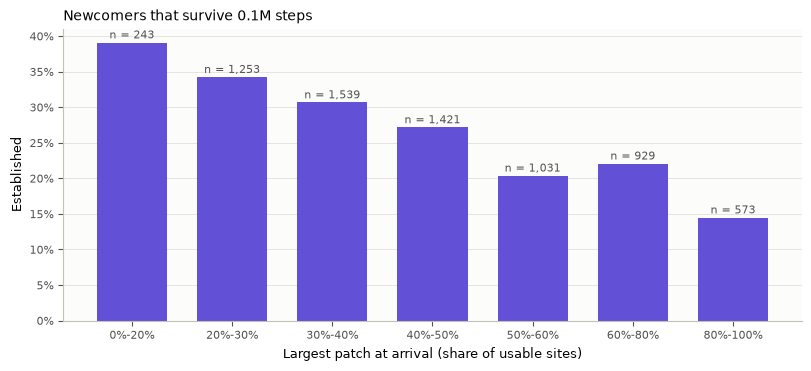

In [6]:
def smooth(values):
    return MS._gaussian_smooth(np.asarray(values, dtype=np.float64), SMOOTH)


with plt.rc_context(RESULT_STYLE):
    fig, axes = plt.subplots(2, 1, figsize=(15, 6.2), sharex=True, layout="constrained",
                             gridspec_kw={"height_ratios": [1, 1.6]})
    axes[0].axhspan(LOW, HIGH, color=BAND_COLOR, lw=0)
    axes[0].plot(t_m, smooth_d, color=SPECIES_COLOR, lw=1.6)
    axes[0].set(ylabel="Living species", title="Living species (smoothed), for orientation")
    for key, ls, label in (("largest_patch_share", "-", "Largest patch"),
                           ("single_patch_share", "--", "Single-patch species"),
                           ("top_share", ":", "Uninvadable species")):
        line = smooth(features[key])
        axes[1].plot(t_m, line, color=INK, ls=ls, lw=1.5, label=label)
    axes[1].set(ylabel="Share of usable sites", ylim=(0, 1), xlabel="t (millions of steps)",
                title="How much of the lattice is held by the largest patch, by single-patch species "
                      "and by uninvadable species")
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    axes[1].legend(loc="lower left", ncols=3)
    for ax in axes:
        for index in SNAPSHOTS.values():
            ax.axvline(t_m[index], color=INK, lw=0.8, ls=":")
    plt.show()

# The species holding the most sites in each state, and how often that changes hands.
dominant = np.array([species_id[a + int(np.argmax(features["abundance"][a:b]))]
                     for a, b in zip(offsets[:-1], offsets[1:])])
handovers = np.r_[False, dominant[1:] != dominant[:-1]]
PHASES = {"Low, before the rise": (t_m[0], RISE / 1e6), "High": (RISE / 1e6, COLLAPSE / 1e6),
          "Low, after the collapse": (COLLAPSE / 1e6, t_m[-1] + 1)}
# Frozen: no boundary in the state across which any invasion is possible.
print(f"{'phase':24s} {'largest patch':>13s} {'single-patch':>12s} {'uninvadable':>11s} "
      f"{'patches/species':>15s} {'frozen':>6s} {'new dominant/1M':>15s} {'established':>11s}")
for name, (start, stop) in PHASES.items():
    inside = (t_m >= start) & (t_m < stop)
    arriving = judged & (arrival_t >= start) & (arrival_t < stop)
    span = min(stop, t_m[-1]) - start
    print(f"{name:24s} {features['largest_patch_share'][inside].mean():13.0%} "
          f"{features['single_patch_share'][inside].mean():12.0%} "
          f"{features['top_share'][inside].mean():11.0%} "
          f"{np.mean(patches[inside] / diversity[inside]):15.1f} "
          f"{np.mean(features['active_boundaries'][inside] == 0):6.0%} "
          f"{handovers[inside].sum() / span:15.0f} {established[arriving].mean():11.0%}")
low_index = SNAPSHOTS["Low after the collapse"]
holder = dominant[low_index]
holder_arrival = int(np.searchsorted(features["introduced"], holder))
print(f"At snapshot 5 the dominant species ({holder}) holds "
      f"{features['largest_share'][low_index]:.0%} of the sites; it arrived between "
      f"{t_m[holder_arrival - 1]:.3f}M and {t_m[holder_arrival]:.3f}M, at most "
      f"{(low_index - holder_arrival + 1) * plan['track_every']:,} steps earlier")
largest_patch = smooth(features["largest_patch_share"])
for name, (lo, hi) in WINDOWS.items():
    patch_half, species_half = half_way(largest_patch, lo, hi), timing[name]["half species"]
    print(f"{name}: the largest patch goes from {largest_patch[lo]:.0%} to {largest_patch[hi]:.0%} of "
          f"the sites and makes half of that change at {t_m[patch_half]:.3f}M, living species at "
          f"{t_m[species_half]:.3f}M ({t_m[species_half] - t_m[patch_half]:+.2f}M later)")

share_edges = np.array([0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0001])
at_arrival = features["largest_patch_share"][np.minimum(arrival, times.size - 1)]
group = np.digitize(at_arrival, share_edges) - 1
rates = [established[judged & (group == k)].mean() for k in range(share_edges.size - 1)]
sizes = [np.count_nonzero(judged & (group == k)) for k in range(share_edges.size - 1)]
with plt.rc_context(RESULT_STYLE):
    fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
    labels = [f"{lo:.0%}-{min(hi, 1):.0%}" for lo, hi in zip(share_edges[:-1], share_edges[1:])]
    ax.set_axisbelow(True)
    ax.grid(axis="x", visible=False)
    bars = ax.bar(labels, rates, color=SPECIES_COLOR, width=0.7)
    for bar, size in zip(bars, sizes):
        ax.annotate(f"n = {size:,}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=INK)
    ax.set(xlabel="Largest patch at arrival (share of usable sites)", ylabel="Established",
           title=f"Newcomers that survive {ESTABLISHED / 1e6:g}M steps")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    plt.show()

## 6. The interaction network: cycles

Species lie on a directed cycle when they share a strongly connected component of Γ with others (every
such cycle has length ≥ 7 here). In a random network with link probability γ a large component appears
once γ·D exceeds about 1, at D ≈ 33 for γ = 0.03. The question is whether cycles appear before the rise,
which would make them a cause, or only with the species count. Left: the share of living species on a
cycle against living species, during the rise (blue) and the collapse (red). Right: the size of the
largest component over the capture.

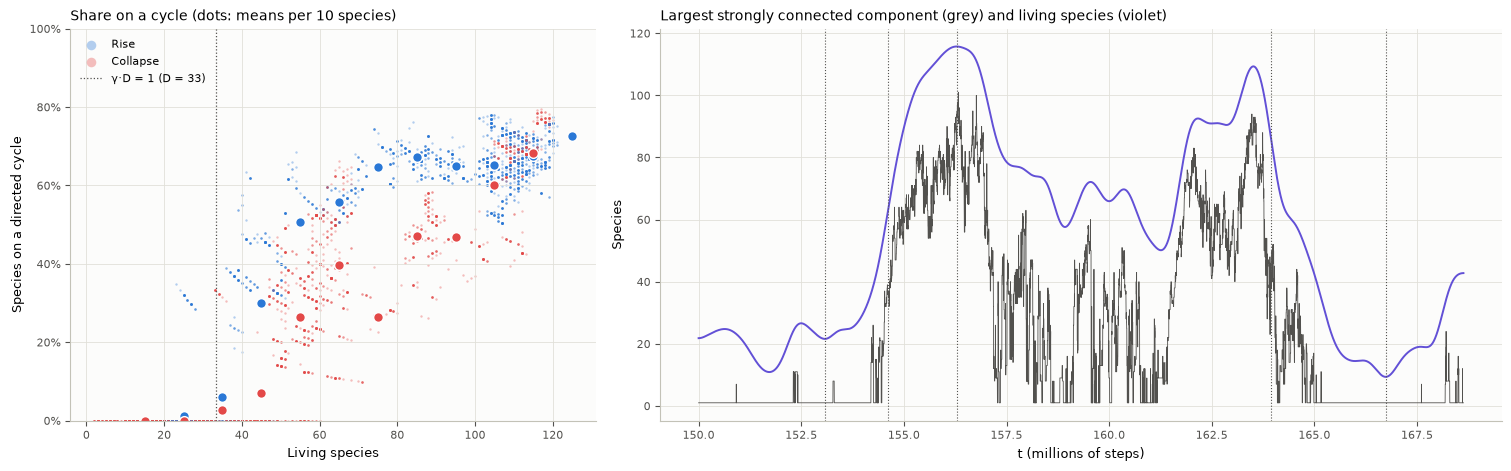

During the rise, a component of 10 or more species first appears at t = 154.197M, with 36 living species; the rise reaches 50 at 154.450M
  Rise     40-60 species: 36% on a cycle (252 states)
  Rise     60-80 species: 60% on a cycle (230 states)
  Rise     80-100 species: 66% on a cycle (356 states)
  Collapse 40-60 species: 19% on a cycle (733 states)
  Collapse 60-80 species: 38% on a cycle (326 states)
  Collapse 80-100 species: 47% on a cycle (196 states)


In [7]:
on_cycles = features["scc_species"] / np.maximum(diversity, 1)
with plt.rc_context(RESULT_STYLE):
    fig, (ax_share, ax_time) = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained",
                                            gridspec_kw={"width_ratios": [1, 1.6]})
    for (name, (lo, hi)), color in zip(WINDOWS.items(), (RISE_COLOR, COLLAPSE_COLOR)):
        ax_share.scatter(diversity[lo:hi + 1], on_cycles[lo:hi + 1], s=3, color=color, alpha=0.35,
                         lw=0, label=name)
        for start in range(10, 130, 10):
            inside = (diversity[lo:hi + 1] >= start) & (diversity[lo:hi + 1] < start + 10)
            if inside.sum() >= 20:
                ax_share.plot(start + 5, on_cycles[lo:hi + 1][inside].mean(), "o", color=color,
                              ms=7, mec="white")
    ax_share.axvline(1 / settings["gamma"], color=INK, lw=0.9, ls=":",
                     label=f"γ·D = 1 (D = {1 / settings['gamma']:.0f})")
    ax_share.set(xlabel="Living species", ylabel="Species on a directed cycle",
                 title="Share on a cycle (dots: means per 10 species)", ylim=(0, 1))
    ax_share.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    ax_share.legend(loc="upper left", markerscale=4)
    ax_time.plot(t_m, features["scc_largest"], color=INK, lw=0.6)
    ax_time.plot(t_m, smooth_d, color=SPECIES_COLOR, lw=1.4)
    ax_time.set(xlabel="t (millions of steps)", ylabel="Species",
                title="Largest strongly connected component (grey) and living species (violet)")
    for index in SNAPSHOTS.values():
        ax_time.axvline(t_m[index], color=INK, lw=0.8, ls=":")
    plt.show()

rise_lo, rise_hi = WINDOWS["Rise"]
first = rise_lo + int(np.argmax(features["scc_largest"][rise_lo:rise_hi + 1] >= 10))
print(f"During the rise, a component of 10 or more species first appears at t = {t_m[first]:.3f}M, "
      f"with {diversity[first]:.0f} living species; the rise reaches {HIGH} at {RISE / 1e6:.3f}M")
for name, (lo, hi) in WINDOWS.items():
    for start in (40, 60, 80):
        inside = (diversity[lo:hi + 1] >= start) & (diversity[lo:hi + 1] < start + 20)
        print(f"  {name:8s} {start}-{start + 20} species: {on_cycles[lo:hi + 1][inside].mean():.0%} "
              f"on a cycle ({inside.sum()} states)")

## 7. Who makes up each community

Each row is one snapshot: its living species placed at their arrival time, sized by the sites they hold.
Species that were alive before the capture began are drawn at the left edge.

1. Before the rise          13 species; 100% of those arrived in the 1M steps before the snapshot
2. Steepest rise            65 species; 100% of those arrived in the 1M steps before the snapshot
3. High diversity          120 species; 73% of those arrived in the 1M steps before the snapshot
4. Steepest collapse        83 species; 76% of those arrived in the 1M steps before the snapshot
5. Low after the collapse    4 species; 100% of those arrived in the 1M steps before the snapshot


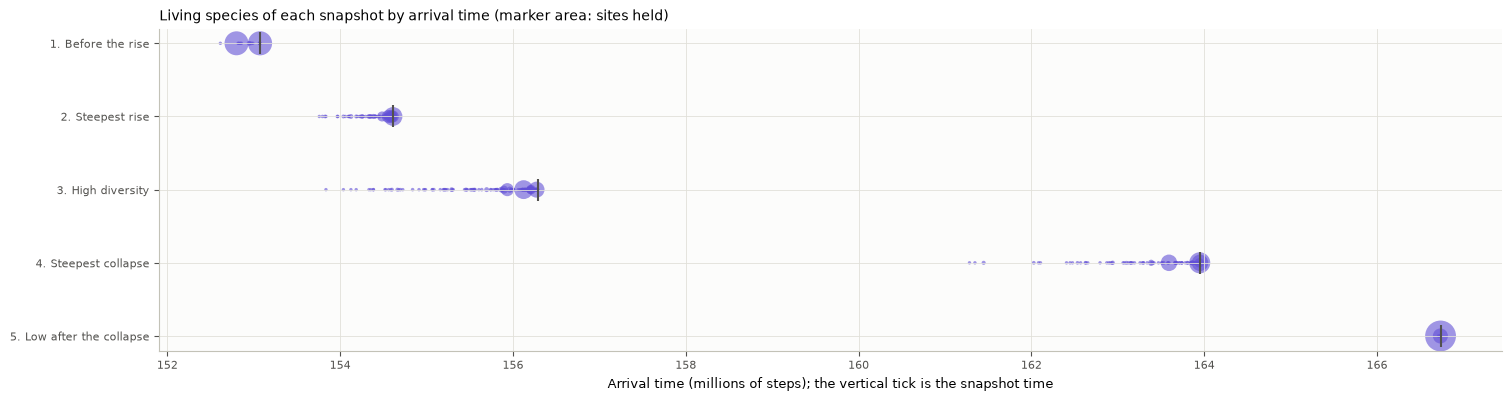

Of the 13 species at snapshot 1, 0 are alive at snapshot 3; 100% of the 120 species at snapshot 3 arrived after snapshot 1
Of the 120 species at snapshot 3, 0 are alive at snapshot 4; the earliest arrival among snapshot 4's 83 species is at 161.28M


In [8]:
first_new = int(features["introduced"][0]) + 1
with plt.rc_context(RESULT_STYLE):
    fig, ax = plt.subplots(figsize=(15, 3.9), layout="constrained")
    for row, (name, index) in enumerate(SNAPSHOTS.items()):
        part = slice(offsets[index], offsets[index + 1])
        ids, held = species_id[part], features["abundance"][part] / settings["usable_sites"]
        when = np.where(ids >= first_new,
                        t_m[np.searchsorted(features["introduced"], ids)], t_m[0] - 0.3)
        ax.scatter(when, np.full(ids.size, row), s=6 + 600 * held, color=SPECIES_COLOR,
                   alpha=0.6, lw=0)
        ax.plot(t_m[index], row, "|", color=INK, ms=16, mew=1.5)
        before = when < t_m[0]
        old = f", {before.sum()} from before 150M" if before.any() else ""
        late = ids >= first_new
        recent = np.mean(when[late] >= t_m[index] - 1.0) if late.any() else 0
        print(f"{row + 1}. {name:23s} {ids.size:3d} species{old}; "
              f"{recent:.0%} of those arrived in the 1M steps before the snapshot")
    ax.set_yticks(range(len(SNAPSHOTS)), [f"{k}. {name}" for k, name in enumerate(SNAPSHOTS, 1)])
    ax.invert_yaxis()
    ax.set(xlabel="Arrival time (millions of steps); the vertical tick is the snapshot time",
           title="Living species of each snapshot by arrival time (marker area: sites held)")
    plt.show()

trough_ids = set(species_id[offsets[i_trough]:offsets[i_trough + 1]].tolist())
peak_index = SNAPSHOTS["High diversity"]
peak_ids = species_id[offsets[peak_index]:offsets[peak_index + 1]]
during = np.searchsorted(features["introduced"], peak_ids) >= i_trough
print(f"Of the {len(trough_ids)} species at snapshot 1, {len(trough_ids & set(peak_ids.tolist()))} "
      f"are alive at snapshot 3; {during.mean():.0%} of the {peak_ids.size} species at snapshot 3 "
      f"arrived after snapshot 1")
fall_index = SNAPSHOTS["Steepest collapse"]
fall_ids = species_id[offsets[fall_index]:offsets[fall_index + 1]]
print(f"Of the {peak_ids.size} species at snapshot 3, "
      f"{np.isin(peak_ids, fall_ids).sum()} are alive at snapshot 4; the earliest arrival among "
      f"snapshot 4's {fall_ids.size} species is at "
      f"{t_m[np.searchsorted(features['introduced'], fall_ids.min())]:.2f}M")

## 8. The rise and the collapse, frame by frame

Eight states evenly spaced over 0.5M steps around the fastest change in patches of each window, as a
preview of the detail the 1,000-step states hold. Titles give the time, living species and patches.

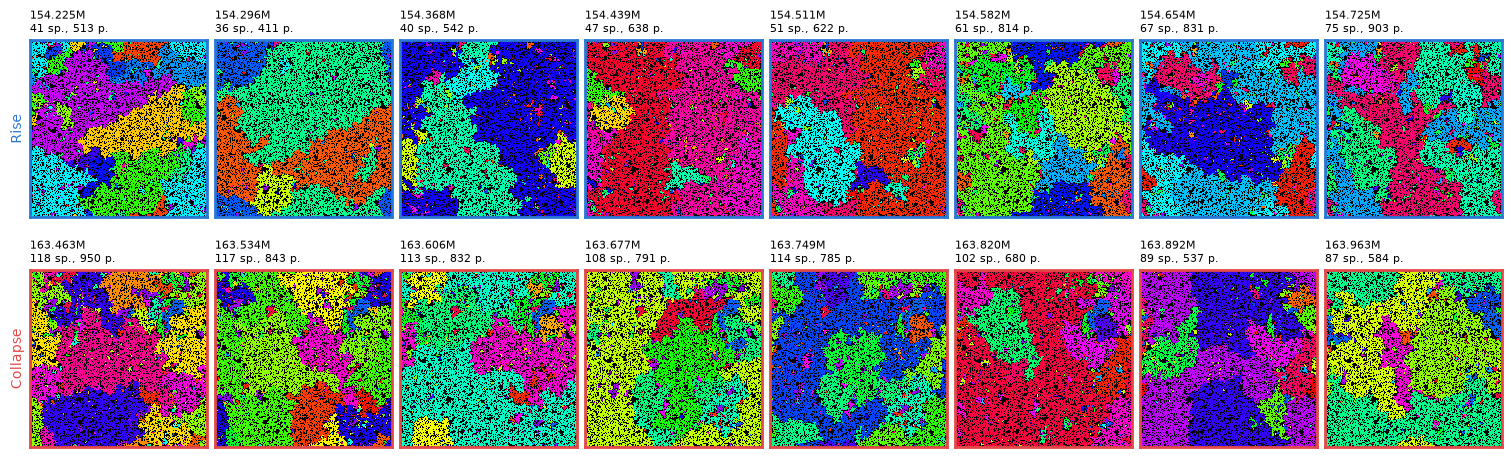

In [9]:
FRAMES, SPAN = 8, 250  # Frames per row; samples either side of the centre (0.25M steps).
with plt.rc_context(RESULT_STYLE):
    fig, axes = plt.subplots(2, FRAMES, figsize=(15, 4.6), layout="constrained")
    for row, (name, color) in enumerate(zip(WINDOWS, (RISE_COLOR, COLLAPSE_COLOR))):
        centre = timing[name]["fastest patches"]
        picks = np.linspace(max(centre - SPAN, 0), min(centre + SPAN, times.size - 1), FRAMES)
        for ax, index in zip(axes[row], picks.round().astype(int)):
            ax.imshow(MS._lattice_rgba(MS.load_checkpoint(STATE_FILES[index])["lattice"]),
                      interpolation="nearest")
            ax.set_title(f"{t_m[index]:.3f}M\n{diversity[index]:.0f} sp., {patches[index]:.0f} p.",
                         fontsize=8)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_edgecolor(color)
                spine.set_linewidth(2)
        axes[row, 0].set_ylabel(name, fontsize=10, color=color)
    plt.show()

## 9. Conclusions

These rest on one rise and one collapse of one run, located on the smoothed living-species curve. The
numbers come from the outputs above.

**The rise (153.08M → 156.28M) begins with the break-up of the largest patch.**
- Before the rise the largest patch covers 62% of the usable sites on average, and species with a single
  patch hold 75%.
- The largest patch then shrinks from 62% to 34% of the sites, half way at 154.25M. Patches follow (half
  way at 154.29M) and living species come last (half way at 154.69M, 0.44M steps after the largest
  patch). This is the order Mitarai et al. describe: patchiness rises first.
- Arrivals stay at 377 per 1M steps throughout, so the rise comes from fewer losses. Before the rise
  7-26% of newcomers survive 0.1M steps (by 0.25M arrival bin); during the rise this reaches 44%.

**Establishment falls as one patch takes more of the lattice.** Newcomers that arrive while the largest
patch covers under 20% of the sites establish in 39% of cases; above 80%, in 14%. By phase: 18% before
the rise, 32% in the high regime, 17% after the collapse.

**The low state is a succession of sweeps.** In the low phases the species holding the most sites changes
229-249 times per 1M steps (189 in the high regime). At snapshot 5 the dominant species holds 81% of the
sites and arrived at most 2,000 steps earlier. A newcomer always invades the species it lands on, so one
that lands in the dominant patch takes it over, and the old dominant dies out if that was its only patch:
one species arrives, one leaves.

**The high-diversity state is a fast flow of newcomers, not a stable assembly.** None of the 13 species at
snapshot 1 is alive at the peak, and all 120 species at the peak arrived after snapshot 1, 73% of them in
the last 1M steps. None of those 120 is alive at snapshot 4: the second high spell is made of species that
arrived from 161.28M on.

**The collapse (163.51M → 166.74M) shows "patchiness first" only at its start.**
- Patches fall fastest at 163.71M and living species at 163.95M, 0.24M later.
- Over the whole collapse, though, living species are half way down at 164.49M, before patches (164.87M)
  and before the largest patch has grown back (from 35% to 72% of the sites, half way at 164.76M). The
  return to one dominant patch goes with the collapse rather than ahead of it.
- Losses peak at 76 species in the 0.1M steps around 164.05M, against 47 arrivals, and establishment falls
  to 2% for newcomers arriving around 166.62M.

**Cycles follow the species count.** Every cycle here is at least 7 species long. A strongly connected
component of 10 or more species first appears at 154.20M, with 36 living species: close to γ·D = 1
(D ≈ 33), where a random network forms one, and at about the time the largest patch breaks up. At the same
species count, fewer species lie on a cycle during the collapse than during the rise (19% against 36% at
40-60 species, 47% against 66% at 80-100). About 80% of the states in every phase are frozen: no boundary
admits any invasion. So the cycles in Γ are rarely acted out on the lattice, and change comes in bursts
after introductions.

**Interpretation.** The measurements fit a feedback through the introduction rule. A newcomer replaces the
patch it lands on. When one patch covers most of the lattice, most introductions replace it wholesale:
diversity stays low while the dominant species keeps changing. When the lattice is broken into many
patches, most introductions land on a small patch of a species that has others, so a species is added
rather than replaced, and the newcomer's small territory is unlikely to be hit by the next newcomer.
Fragmentation raises diversity, and more species keep the lattice fragmented; consolidation works the same
way in reverse. The route the paper emphasises, the collapse of cycles of 4-6 species, is excluded in this
run by construction, and active cycles are rare.

**Open.** These aggregate measures do not show what first breaks up the dominant patch, at about
154.0-154.3M, or what lets one patch grow back from about 163.5M. Candidates are a newcomer followed by its
own invader (the chain A → B → C of the paper), several overlapping sweeps, or a long cycle acted out
briefly. The 1,000-step states in those windows (section 8) are where to look, and they are what the
planned videos should cover.

**Caveats.** One run, with one switch in each direction. Establishment uses a 0.1M-step threshold. Arrival
and loss times are known to 1,000 steps, and "frozen" describes the sampled instant only.